# Analiza foțelor dintr-un pod

În acest program, efectuăm o analiza a forțelor dintr-un pod de tip ”Warren Truss”, evidențiând vizual cum sunt distribuite în structura podului, în momentul aplicării unei sarcini la jumătatea podului

In [83]:
import numpy as np
import matplotlib.pyplot as plt
import time
import scipy.linalg
from matplotlib.lines import Line2D

plt.rcParams['figure.figsize'] = [12, 6]
plt.rcParams['figure.dpi'] = 100

# Generarea podului și a sistemului Ax = b
Funcția generate_bridge_system genereaza podul, crează vectori care memorează nodurile si bările podului, calculează forțele statice din bări și aplică greutatea tancului

Model generat: 51 noduri.
Sistemul rezultat: 102 ecuatii x 102 necunoscute.


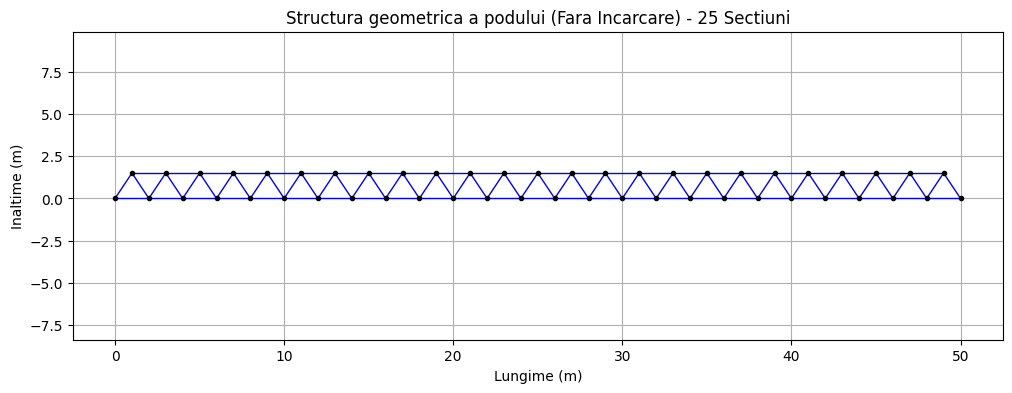

In [84]:
def generate_bridge_system(num_sections):
    """
    Genereaza sistemul Ax=b pentru un pod de tip 'Warren Truss'.
    num_sections: Numarul de segmente triunghiulare.
    Return: A (matricea), b (vectorul incarcari), nodes (coordonate), members (conexiuni)
    """

    #Nota: În cazul în care graficul nu arta bine, schimba culoarea de la plot (linia 103)

    # setari parametrii
    L = 2.0  # Lungimea unui segment (metri)
    H = 1.5  # Inaltimea (metri)
    Load = 10000.0 # Greutatea unui vehicul aplicata pe nodurile centrale (Newtoni)

    #Generare coordonate
    nodes = []
    # Alternam noduri jos (y=0) si sus (y=H)
    for i in range(num_sections + 1):
        nodes.append((i * L, 0))       # Nod Jos
        if i < num_sections:
            nodes.append((i * L + L/2, H)) # Nod Sus
    #   .           .           .
    #.      apoi .      apoi .      ....

    num_nodes = len(nodes)

    #Definire Bare (Conexiuni intre noduri)
    members = []
    # Bare orizontale jos
    for i in range(0, num_nodes - 2, 2):
        members.append((i, i+2))

    # Bare orizontale sus
    for i in range(1, num_nodes - 2, 2):
        members.append((i, i+2))

    # Bare diagonale
    for i in range(num_sections):
        lower_left = 2*i
        upper = 2*i + 1
        lower_right = 2*i + 2
        members.append((lower_left, upper)) #bara /
        members.append((upper, lower_right)) #bara \

    num_members = len(members)

    #Construire Matrice A si Vector b
    # Avem 2 ecuatii per nod (echilibru X si Y).
    # Necunoscute: Fortele din bare (num_members) + 3 Reactiuni (Rx_stanga, Ry_stanga, Ry_dreapta)
    num_eq = 2 * num_nodes
    num_vars = num_members + 3

    A = np.zeros((num_eq, num_vars))
    b = np.zeros(num_eq)

    # Completare Matrice A cu cosinusuri directori
    for k, (node_i, node_j) in enumerate(members):
        xi, yi = nodes[node_i]
        xj, yj = nodes[node_j]
        dist = np.sqrt((xj-xi)**2 + (yj-yi)**2)

        # Cosinus (dx) si Sinus (dy)
        c = (xj - xi) / dist
        s = (yj - yi) / dist

        # Ecuatiile pentru Nodul i
        A[2*node_i, k] += c
        A[2*node_i+1, k] += s

        # Ecuatiile pentru Nodul j (sens opus)
        A[2*node_j, k] -= c
        A[2*node_j+1, k] -= s

    # Adaugare Reactiuni (Suporti)
    # Nod 0 (Stanga Jos): Fixat X si Y
    A[0, num_members] = 1     # Reactiune H
    A[1, num_members+1] = 1   # Reactiune V

    # Ultimul nod de jos: Fixat doar Y (rola)
    last_node_idx = 2 * num_sections
    A[2*last_node_idx+1, num_members+2] = 1

    #Aplicare greutate tanc
    # Aplicam forta pe cateva noduri centrale de jos
    mid_start = num_sections // 2 - 2
    mid_end = num_sections // 2 + 2
    for i in range(mid_start, mid_end):
        if i >= 0 and i*2 < num_nodes:
             b[2*(i*2) + 1] -= Load # Forta in jos pe axa Y

    return A, b, nodes, members

#Grafice
# Generam un pod cu 25 sectiuni (aprox 100+ ecuatii)
NUM_SECTIUNI = 25
A, b, nodes, members = generate_bridge_system(NUM_SECTIUNI)

print(f"Model generat: {len(nodes)} noduri.")
print(f"Sistemul rezultat: {A.shape[0]} ecuatii x {A.shape[1]} necunoscute.")

# Plotare "Schelet" Pod
plt.figure(figsize=(12, 4))
for (i, j) in members:
    p1, p2 = nodes[i], nodes[j]
    plt.plot([p1[0], p2[0]], [p1[1], p2[1]], 'b-', lw=1) # Linii negre simple, schimba culoarea daca face fite IDE-ul

plt.plot([n[0] for n in nodes], [n[1] for n in nodes], 'ko', markersize=3)
plt.title(f"Structura geometrica a podului (Fara Incarcare) - {NUM_SECTIUNI} Sectiuni")
plt.xlabel("Lungime (m)")
plt.ylabel("Inaltime (m)")
plt.axis('equal')
plt.grid(True)
plt.show()

# Definirea algoritmilor
Definim UTRIS și GPP

In [85]:
def UTRIS(U, b):
    n = len(b)
    x = np.zeros(n)
    for i in range(n - 1, -1, -1):
        s = sum(U[i][j] * x[j] for j in range(i + 1, n))
        if abs(U[i][i]) < 1e-15:
            # Protectie minimala la impartire la zero
            continue
        x[i] = (b[i] - s) / U[i][i]
    return x

def gauss_no_pivoting(A_in, b_in):

    A = A_in.copy()
    b = b_in.copy()
    n = len(b)
    n_vars = A.shape[1]
    limit = min(n, n_vars)

    for k in range(limit):
        pivot = A[k, k]

        # Check: daca pivotul e 0, pa pa Gauss.
        if abs(pivot) < 1e-15:
            continue

        for i in range(k + 1, n):
            factor = A[i, k] / pivot
            A[i, k:] -= factor * A[k, k:]
            b[i] -= factor * b[k]

    return UTRIS(A[:n_vars, :n_vars], b[:n_vars])

def gauss_partial_pivoting(A_in, b_in):

    A = A_in.copy()
    b = b_in.copy()
    n = len(b)
    n_vars = A.shape[1]
    limit = min(n, n_vars)

    for k in range(limit):
        #Cautam maximul pe coloana pentru stabilitate
        pivot_index = k + np.argmax(np.abs(A[k:, k]))

        if abs(A[pivot_index, k]) < 1e-15:
            continue

        if pivot_index != k:
            A[[k, pivot_index]] = A[[pivot_index, k]]
            b[[k, pivot_index]] = b[[pivot_index, k]]

        # Eliminare
        for i in range(k + 1, n):
            factor = A[i, k] / A[k, k]
            A[i, k:] -= factor * A[k, k:]
            b[i] -= factor * b[k]

    return UTRIS(A[:n_vars, :n_vars], b[:n_vars])

# Analiza Numerică
Utilizăm algoritmii definiți mai sus, memorăm rezultatele și timpii de execuție

In [86]:
print("\n" + "="*80)
print(f"{'METODA':<20} | {'TIMP (s)':<12} | {'REZIDUU ||Ax-b||':<20} | {'EROARE vs NumPy':<20}")
print("-" * 80)

# Calculam pentru o dimensiune fixa
A_analiza, b_analiza, _, _ = generate_bridge_system(50)

# NumPy
t_start = time.time()
x_ref = np.linalg.solve(A_analiza, b_analiza)
t_np = time.time() - t_start
res_np = np.linalg.norm(np.dot(A_analiza, x_ref) - b_analiza)
print(f"{'NumPy Standard':<20} | {t_np:.5f}        | {res_np:.5e}            | {'-':<20}")

# Gauss GPP
t_start = time.time()
x_gpp = gauss_partial_pivoting(A_analiza, b_analiza)
t_gpp = time.time() - t_start
res_gpp = np.linalg.norm(np.dot(A_analiza, x_gpp) - b_analiza)
err_gpp = np.linalg.norm(x_gpp - x_ref)
print(f"{'Gauss Pivotare':<20} | {t_gpp:.5f}        | {res_gpp:.5e}            | {err_gpp:.5e}")

#Gauss naiv fara pivotare
try:
    t_start = time.time()
    x_naiv = gauss_no_pivoting(A_analiza, b_analiza)
    t_naiv = time.time() - t_start
    res_naiv = np.linalg.norm(np.dot(A_analiza, x_naiv) - b_analiza)
    err_naiv = np.linalg.norm(x_naiv - x_ref)
    print(f"{'Gauss Naiv':<20} | {t_naiv:.5f}        | {res_naiv:.5e}            | {err_naiv:.5e}")
except Exception as e:
    print(f"{'Gauss Naiv':<20} | EȘUAT! ({e})")
print("="*80)

#Analiza Matricei
total_elements = A.size
non_zero_elements = np.count_nonzero(A)
sparsity = (1.0 - non_zero_elements / total_elements) * 100
fill_ratio = (non_zero_elements / total_elements) * 100

print(f"\n--- 1. ANALIZA STRUCTURALĂ A MATRICEI ({A.shape[0]}x{A.shape[1]}) ---")
print(f"Total elemente:       {total_elements}")
print(f"Elemente nenule:      {non_zero_elements}")
print(f"Grad de umplere:      {fill_ratio:.2f}% ")
print(f"Grad de raritate:     {sparsity:.2f}% ")

import sys

print(f"\n--- 2. ANALIZA EFICIENȚEI MEMORIEI ---")

# (100x100 float-uri a cate 8 bytes fiecare)
memory_dense = A.nbytes
print(f"Memorie ocupată (Dense): {memory_dense} bytes")

# Memoria teoretica (Sparse)
# format comprimat (CSR), stocam doar valorile nenule si indicii lor.
# Aprox: (Valoare + Index Linie + Index Coloana) per element nenul
memory_sparse_approx = non_zero_elements * (8 + 4 + 4)
print(f"Memorie necesară (Optimazare Sparse): {memory_sparse_approx} bytes")


METODA               | TIMP (s)     | REZIDUU ||Ax-b||     | EROARE vs NumPy     
--------------------------------------------------------------------------------
NumPy Standard       | 0.00054        | 5.00523e-10            | -                   
Gauss Pivotare       | 0.03863        | 3.13461e-10            | 1.10745e-09
Gauss Naiv           | 0.00493        | 2.00000e+04            | 3.84387e+06

--- 1. ANALIZA STRUCTURALĂ A MATRICEI (102x102) ---
Total elemente:       10404
Elemente nenule:      301
Grad de umplere:      2.89% 
Grad de raritate:     97.11% 

--- 2. ANALIZA EFICIENȚEI MEMORIEI ---
Memorie ocupată (Dense): 83232 bytes
Memorie necesară (Optimazare Sparse): 4816 bytes


# Generarea graficelor
Plotăm graficele relevante

Nr Ecuatii      | Naive (s)    | GPP (s)      | NumPy (s)   
------------------------------------------------------------
42              | 0.00032        | 0.00211        | 0.00047
82              | 0.00098        | 0.00819        | 0.00069
122             | 0.00253        | 0.01517        | 0.00544
162             | 0.00329        | 0.02508        | 0.00392
202             | 0.00513        | 0.04121        | 0.00770
242             | 0.00732        | 0.05890        | 0.01115


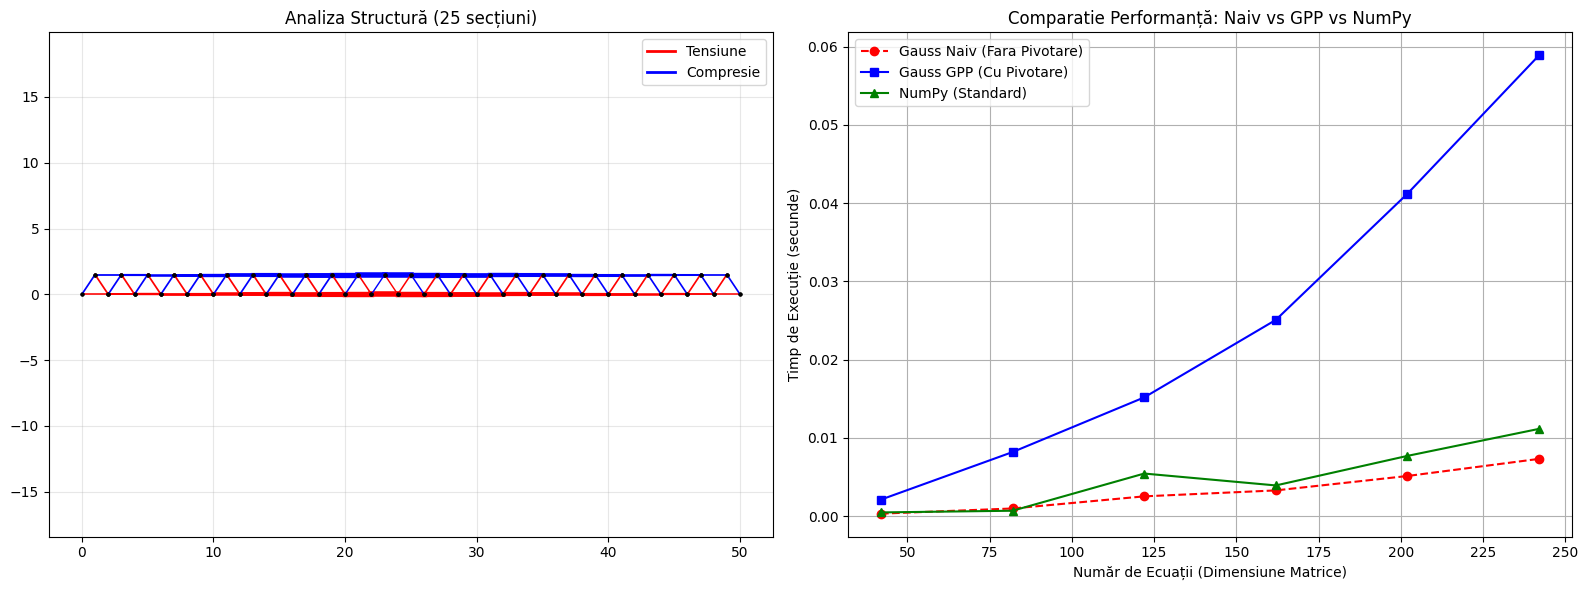

In [87]:
import time
from matplotlib.lines import Line2D

# 1. Generam un pod mare pentru testul vizual
NUM_SECTIUNI = 25
A, b, nodes, members = generate_bridge_system(NUM_SECTIUNI)

# Rezolvam cu GPP pentru desenarea podului (cea mai sigura metoda custom)
x_sol = gauss_partial_pivoting(A, b)

plt.figure(figsize=(16, 6))

# --- GRAFIC 1: Harta de Tensiune (Vizualizare Pod) ---
plt.subplot(1, 2, 1)
forces = x_sol[:len(members)]
max_force = np.max(np.abs(forces))

for k, (i, j) in enumerate(members):
    xi, yi = nodes[i]
    xj, yj = nodes[j]
    f = forces[k]
    color = 'red' if f < 0 else 'blue'
    width = 1 + 3 * (abs(f) / max_force)
    plt.plot([xi, xj], [yi, yj], color=color, linewidth=width)
    plt.plot(xi, yi, 'ko', markersize=2)
    plt.plot(xj, yj, 'ko', markersize=2)

legend_elements = [
    Line2D([0], [0], color='red', lw=2, label='Tensiune'),
    Line2D([0], [0], color='blue', lw=2, label='Compresie')
]
plt.legend(handles=legend_elements, loc='upper right')
plt.title(f"Analiza Structură ({NUM_SECTIUNI} secțiuni)")
plt.axis('equal')
plt.grid(True, alpha=0.3)

# --- GRAFIC 2: Comparație Performanță (Cele 3 Metode) ---
plt.subplot(1, 2, 2)

# Definim marimile de test (numar sectiuni)
test_sizes = [10, 20, 30, 40, 50, 60]

# Liste pentru timpi
times_naive = []
times_gpp = []
times_numpy = []
eq_counts = []

print(f"{'Nr Ecuatii':<15} | {'Naive (s)':<12} | {'GPP (s)':<12} | {'NumPy (s)':<12}")
print("-" * 60)

for s in test_sizes:
    # Generare sistem
    A_test, b_test, _, _ = generate_bridge_system(s)
    N = A_test.shape[0]
    eq_counts.append(N)

    # 1. Gauss Naiv (Fara Pivotare)
    try:
        t0 = time.time()
        gauss_no_pivoting(A_test, b_test)
        times_naive.append(time.time() - t0)
    except Exception as e:
        times_naive.append(None) # Daca crapa (impartire la 0)

    # 2. Gauss GPP (Cu Pivotare)
    t0 = time.time()
    gauss_partial_pivoting(A_test, b_test)
    times_gpp.append(time.time() - t0)

    # 3. NumPy (Standard)
    t0 = time.time()
    np.linalg.lstsq(A_test, b_test, rcond=None)
    times_numpy.append(time.time() - t0)

    print(f"{N:<15} | {times_naive[-1]:.5f}        | {times_gpp[-1]:.5f}        | {times_numpy[-1]:.5f}")

# Plotare Linii
plt.plot(eq_counts, times_naive, 'r--o', label='Gauss Naiv (Fara Pivotare)')
plt.plot(eq_counts, times_gpp, 'b-s', label='Gauss GPP (Cu Pivotare)')
plt.plot(eq_counts, times_numpy, 'g-^', label='NumPy (Standard)')

plt.title("Comparatie Performanță: Naiv vs GPP vs NumPy")
plt.xlabel("Număr de Ecuații (Dimensiune Matrice)")
plt.ylabel("Timp de Execuție (secunde)")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()